# Image inference

Find nuclei in a tissue image using a pretrained CellPose model, then view and
save the masks. Each instance label identifies one nucleus. A class label gives
its predicted category.

Run this notebook from `docs/tutorials/` in a clone of the repository. It uses the
included tissue image and downloads the
[HGSC checkpoint](https://huggingface.co/csmp-hub/cellpose-histo-hgsc-nuc-v1)
on the first run. The weights are released under Apache 2.0.

The notebook uses a CUDA GPU when available and otherwise uses CPU. This small
example shows the workflow; check results on your own images before relying on them.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from huggingface_hub import hf_hub_download
from PIL import Image
from skimage.color import label2rgb

from cellseg_models_pytorch.inference.post_processor import PostProcessor
from cellseg_models_pytorch.models.cellpose import CellPose
from cellseg_models_pytorch.transforms.functional.normalization import minmax_normalize

torch.set_num_threads(2)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

# Use the tissue image included in the repository; replace this path with your image.
image_path = Path("../../cellseg_models_pytorch/utils/tests/data/HE.png")
# Resize this demonstration to 1024 pixels; match image scale to your own checkpoint.
with Image.open(image_path) as source:
    tissue_image = source.convert("RGB").resize((1024, 1024), Image.Resampling.BILINEAR)

# This checkpoint expects RGB pixels normalized together to the range 0–1.
image = minmax_normalize(np.asarray(tissue_image), copy=True)


Device: cuda


In [2]:
# Pin the weights so this example uses the same model on each run.
checkpoint_path = Path(hf_hub_download(
    repo_id="csmp-hub/cellpose-histo-hgsc-nuc-v1",
    filename="cellpose_hgsc_v1_efficientnet_b5.safetensors",
    revision="88c7ffd3a9106d1673c3dd6e6a9e42476e8320d2",
))

model = CellPose.from_pretrained(checkpoint_path, device=device)
model.set_inference_mode(mixed_precision=False)
model.post_processor = PostProcessor("cellpose", {"use_gpu": device.type == "cuda"})

# Prediction produces dense maps; post-processing separates individual nuclei.
prediction = model.predict(image)
result = model.post_process(prediction, use_async_postproc=False)
instances, classes = result["nuc"][0]

print("Instance count:", len(np.unique(instances[instances > 0])))


Instance count: 244


`instances` has the same height and width as the resized image. Zero means
background; each positive number identifies one nucleus. `classes` gives each
nucleus a category number. See the model card for the category names.

For your own image, use the preprocessing specified for your checkpoint. Image
width and height must be multiples of 32. This demo uses 1024 × 1024 pixels. Resizing changes the apparent size of nuclei;
for your own data, match the image resolution used to train your checkpoint.

For larger images, `predict(..., use_sliding_win=True, window_size=(256, 256),
stride=128)` predicts overlapping tiles. Start with this single-image workflow
before working with larger images.


## View the masks

The first panel shows the image. The second gives each instance a colour, and
the third gives objects of the same class the same colour. Background is black.
The colours only display label numbers; use your checkpoint's class mapping to
interpret them.

You should see coloured shapes following nuclei in the tissue image. Predictions
are imperfect, so compare the masks with the image when checking your own results.


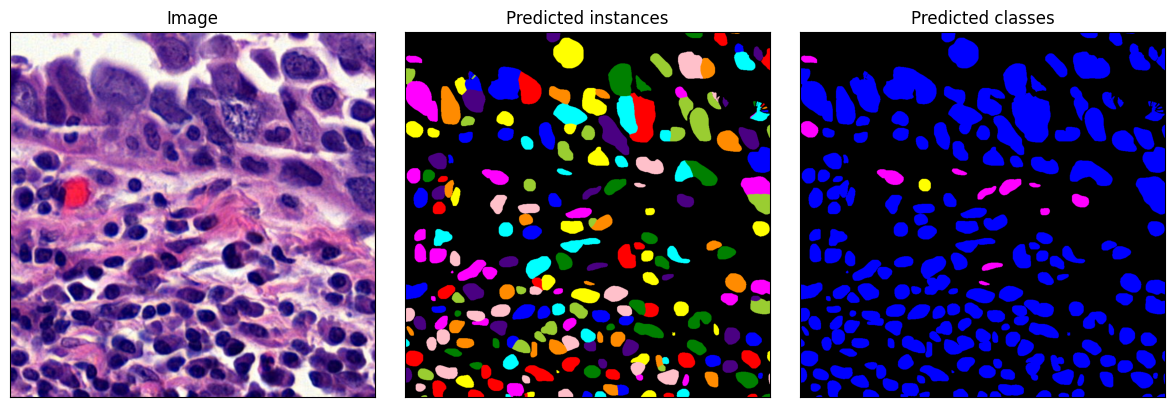

In [3]:
instance_colors = label2rgb(instances, bg_label=0)

# Class 0 can describe an object, so use the instance mask to find background.
class_colors = label2rgb(classes, bg_label=-1)
class_colors[instances == 0] = 0

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(image)
axes[0].set(title="Image", xticks=[], yticks=[])

axes[1].imshow(instance_colors)
axes[1].set(title="Predicted instances", xticks=[], yticks=[])

axes[2].imshow(class_colors)
axes[2].set(title="Predicted classes", xticks=[], yticks=[])

fig.tight_layout()
plt.show()

## Save the masks

Choose a new output file so an existing result is not overwritten.

In [4]:
# Preserve labels without lossy image conversion; do not overwrite an existing result.
output_path = Path("segmentation.npz")

# Uncomment to save after choosing a destination:
# with output_path.open("xb") as output:
#     np.savez_compressed(output, instances=instances, classes=classes)